# Práctica 1 – Redes neuronales (NN) sobre EuroSAT
**Aprendizaje Profundo (Grado en IA) – Curso 2026-2027**

**Autores:** Pedro Agrelo Márquez, Sneshanka Blanca Andrés Ochoa
**Grupo de prácticas:** Grupo 15

## 0. Introducción y objetivo

El objetivo es clasificar imágenes de satélite (Sentinel-2) del dataset **EuroSAT** en 10 clases de uso del suelo usando únicamente **redes neuronales densas ("vanilla")**, sin capas convolucionales. 

Plan del cuaderno:

1. Carga y exploración del dataset.
2. Preprocesado: partición train/val/test, normalización a [0, 1], aplanado y one-hot.
3. Modelo base (sin regularización) para observar el sobreaprendizaje.
4. Técnicas de regularización por separado: L2, Dropout, BatchNorm y Early Stopping.
5. Modelo combinado con las técnicas que mejor funcionan.
6. Optimización: comparación de optimizadores (SGD, RMSprop y Adam).
7. Evaluación final del mejor modelo en test y comparación de todos los modelos.

**Criterio de selección:** los modelos se comparan y se elige el mejor usando el conjunto de **validación**. El conjunto de **test** solo se usa para informar del rendimiento final (se calcula también para todos los modelos para poder rellenar la tabla resumen, pero no se ha usado para tomar decisiones).

## 1. Imports y semillas

In [5]:
# Solo hace falta en algunos entornos (p. ej. Colab) para que tensorflow_datasets pueda descargar el dataset
%pip install -q importlib_resources

In [6]:
import os, glob, random, shutil, urllib.request, urllib.error, zipfile, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import keras
from keras import layers
from keras import regularizers
from keras.callbacks import EarlyStopping
import tensorflow as tf
import tensorflow_datasets as tfds
from sklearn.metrics import confusion_matrix, classification_report

# Fijamos la semilla para poder reproducir los resultados
seed = 1234
os.environ['PYTHONHASHSEED'] = str(seed)
tf.random.set_seed(seed)
np.random.seed(seed)
random.seed(seed)

def fijar_semilla():
    """Misma semilla antes de crear cada modelo, para que todos partan de las mismas condiciones."""
    os.environ['PYTHONHASHSEED'] = str(seed)
    tf.random.set_seed(seed)
    np.random.seed(seed)
    random.seed(seed)
    keras.utils.set_random_seed(seed)

print("Keras:", keras.__version__, "| TensorFlow:", tf.__version__)
print("GPUs disponibles:", tf.config.list_physical_devices("GPU"))
if not tf.config.list_physical_devices("GPU"):
    print("AVISO: no hay GPU.")

Keras: 3.13.2 | TensorFlow: 2.21.0
GPUs disponibles: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Carga del dataset

Siguiendo los laboratorios, el dataset se carga con **TensorFlow Datasets** (`eurosat/rgb`). EuroSAT solo tiene una partición (`train`, 27 000 imágenes), así que la dividimos con la sintaxis de porcentajes de `tfds.load`, igual que en el ejercicio del Lab 4:

- `train[:70%]` → entrenamiento
- `train[70%:85%]` → validación
- `train[85%:]` → test

**Método alternativo (zip local):** TFDS descarga el dataset del servidor del autor (`madm.dfki.de`), que a veces no responde (por ejemplo desde Colab). Por eso el código busca primero un zip o carpeta de EuroSAT que hayas subido a mano (cualquier nombre que contenga `EuroSAT`, p. ej. `EuroSAT_RGB.zip`, en la carpeta de trabajo, en `/content` o en tu Drive). Si no hay ninguno, se usa TFDS. En ambos casos se construyen las mismas particiones 70/15/15, de modo que el resto del cuaderno funciona igual.


In [7]:
TAM_LOTE = 128
SPLITS = {'train': 'train[:70%]', 'val': 'train[70%:85%]', 'test': 'train[85%:]'}

def tfds_disponible():
    """True si el dataset ya está descargado o si el servidor de TFDS responde."""
    if glob.glob(os.path.expanduser('~/tensorflow_datasets/eurosat/rgb/*/dataset_info.json')):
        return True
    try:
        req = urllib.request.Request("https://madm.dfki.de/files/sentinel/EuroSAT.zip", method="HEAD")
        urllib.request.urlopen(req, timeout=10)
        return True
    except urllib.error.HTTPError:
        return True      # el servidor responde (aunque rechace el HEAD)
    except Exception as e:
        print("El servidor de descarga de TFDS (madm.dfki.de) no responde:", type(e).__name__)
        return False

# ---------- Método 1: zip (o carpeta) de EuroSAT subido a mano ----------
def tiene_imagenes(carpeta):
    return any(f.lower().endswith((".jpg", ".jpeg", ".png")) for _, _, fs in os.walk(carpeta) for f in fs)

def buscar_dataset_local():
    """Busca un zip (o una carpeta ya descomprimida) de EuroSAT subido a mano, p. ej. al panel de archivos de Colab.
    Acepta cualquier nombre que contenga 'eurosat' (EuroSAT_RGB.zip, EuroSAT.zip, 'EuroSAT_RGB (1).zip', ...)."""
    bases, vistos = [os.getcwd(), '/content', '/content/drive/MyDrive', os.path.expanduser('~')], set()
    for base in bases:
        if not os.path.isdir(base) or base in vistos:
            continue
        vistos.add(base)
        for patron in ('*', '*/*'):
            for ruta in sorted(glob.glob(os.path.join(base, patron))):
                nombre = os.path.basename(ruta).lower()
                if 'eurosat' not in nombre or nombre.endswith(('_ms.zip', '_ms')) or 'tensorflow_datasets' in ruta:
                    continue
                if os.path.isfile(ruta) and zipfile.is_zipfile(ruta):
                    return ruta
                if os.path.isfile(ruta):
                    print(f"Aviso: {ruta} ({os.path.getsize(ruta)/1e6:.0f} MB) no es un zip válido (¿subida incompleta?)")
                if os.path.isdir(ruta) and tiene_imagenes(ruta):
                    return ruta
    return None

def cargar_imagenes(ruta):
    """Devuelve (imágenes uint8, etiquetas, nombres de clase) a partir de un zip o carpeta de EuroSAT.
    Cada carpeta que contiene imágenes se interpreta como una clase."""
    from PIL import Image
    if os.path.isfile(ruta):
        # Copiamos el zip al disco local y comprobamos que está completo antes de leerlo
        # (los zips subidos a medias, o leídos desde Drive, dan errores de lectura raros)
        tam = os.path.getsize(ruta) / 1e6
        print(f"Usando {ruta} ({tam:.0f} MB)")
        try:
            shutil.copyfile(ruta, "EuroSAT_local.zip")
            with zipfile.ZipFile("EuroSAT_local.zip") as z:
                malo = z.testzip()
                if malo is not None:
                    raise zipfile.BadZipFile(f"fichero dañado dentro del zip: {malo}")
                z.extractall("EuroSAT_raw")
        except (OSError, zipfile.BadZipFile) as e:
            raise RuntimeError(
                f"El zip {ruta} ({tam:.0f} MB) está incompleto o dañado ({type(e).__name__}: {e}). "
                "El zip RGB de EuroSAT pesa unos 90 MB. Bórralo del panel de archivos, vuelve a subirlo esperando a que "
                "termine la subida del todo (o cópialo desde tu Drive con shutil.copy) y ejecuta de nuevo la celda.") from e
        carpeta = "EuroSAT_raw"
    else:
        carpeta = ruta
    imgs, labs, names = [], [], []
    for root, _, files in sorted(os.walk(carpeta)):
        if "__MACOSX" in root:
            continue
        jpgs = sorted(f for f in files if f.lower().endswith((".jpg", ".jpeg", ".png")) and not f.startswith("."))
        if not jpgs:
            continue
        names.append(os.path.basename(root))
        for f in jpgs:
            imgs.append(np.array(Image.open(os.path.join(root, f)).convert("RGB")))
            labs.append(len(names) - 1)
    return np.stack(imgs).astype(np.uint8), np.array(labs, dtype=np.int64), names

def particiones_desde_arrays(X, y):
    """Mismo reparto 70/15/15 que con TFDS (tras mezclar con la semilla), devuelto como tf.data.Dataset."""
    idx = np.random.default_rng(seed).permutation(len(y))
    n_tr, n_va = int(0.70 * len(y)), int(0.85 * len(y))
    partes = {'train': idx[:n_tr], 'val': idx[n_tr:n_va], 'test': idx[n_va:]}
    return {k: tf.data.Dataset.from_tensor_slices((X[i], y[i])) for k, i in partes.items()}

In [8]:
ruta_local = buscar_dataset_local()      # si hay un zip con el dataset en la carpeta del notebook
print("Dataset local encontrado en:", ruta_local)

if ruta_local is not None:
    # Método 1: zip (o carpeta) de EuroSAT subido a mano
    print("Usando el dataset local")
    X_all, y_all, class_names = cargar_imagenes(ruta_local)
    print("Imágenes leídas:", X_all.shape)
    d = particiones_desde_arrays(X_all, y_all)
    ds_train_raw, ds_val_raw, ds_test_raw = d['train'], d['val'], d['test']
    del X_all, y_all
elif tfds_disponible():
    # Método 2: carga con TFDS, como en los laboratorios
    ds_train_raw, info = tfds.load('eurosat/rgb', split=SPLITS['train'], as_supervised=True, with_info=True)
    ds_val_raw  = tfds.load('eurosat/rgb', split=SPLITS['val'],  as_supervised=True)
    ds_test_raw = tfds.load('eurosat/rgb', split=SPLITS['test'], as_supervised=True)
    class_names = info.features['label'].names
    print("Dataset cargado con TFDS")
else:
    raise RuntimeError(
        "No se encontró el dataset y el servidor de TFDS no responde.\n"
        f"  Carpeta de trabajo del cuaderno: {os.getcwd()}\n"
        f"  Contenido: {sorted(os.listdir('.'))[:20]}\n"
        "Sube el zip RGB de EuroSAT (~90 MB) al panel de archivos de Colab (icono de carpeta), espera a que termine la "
        "subida y comprueba que NO se ha reiniciado el entorno de ejecución después (al reiniciarse se borran los "
        "archivos subidos). Cualquier nombre que contenga 'EuroSAT' sirve (p. ej. EuroSAT_RGB.zip).")

NUM_CLASSES = len(class_names)
print("Clases:", class_names)


Dataset local encontrado en: /content/EuroSAT_RGB.zip
Usando el Plan B (zip/carpeta de EuroSAT)
Usando /content/EuroSAT_RGB.zip (95 MB)
Imágenes leídas: (27000, 64, 64, 3)
Clases: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


### 2.1 Exploración

train: 18900 | val: 4050 | test: 4050 | forma de una imagen: (64, 64, 3), uint8

Proporción de cada clase en cada partición:
                      train    val   test
AnnualCrop            0.110  0.111  0.117
Forest                0.109  0.109  0.121
HerbaceousVegetation  0.110  0.119  0.110
Highway               0.091  0.093  0.098
Industrial            0.094  0.087  0.092
Pasture               0.074  0.074  0.073
PermanentCrop         0.096  0.088  0.083
Residential           0.111  0.112  0.113
River                 0.092  0.102  0.086
SeaLake               0.113  0.105  0.106


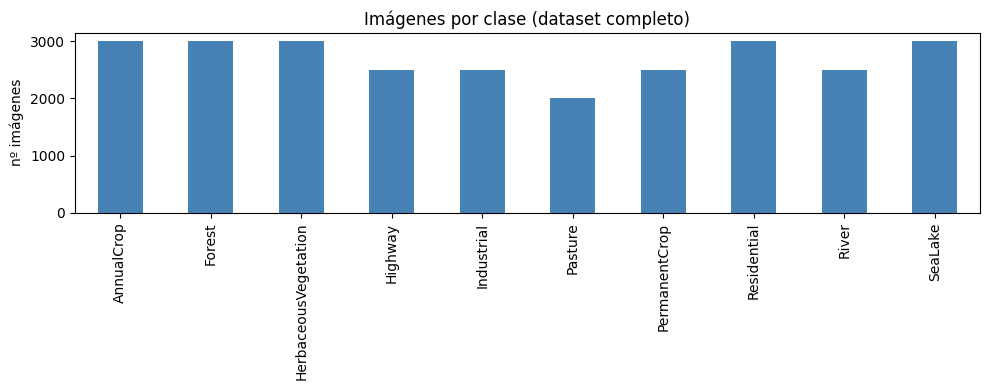

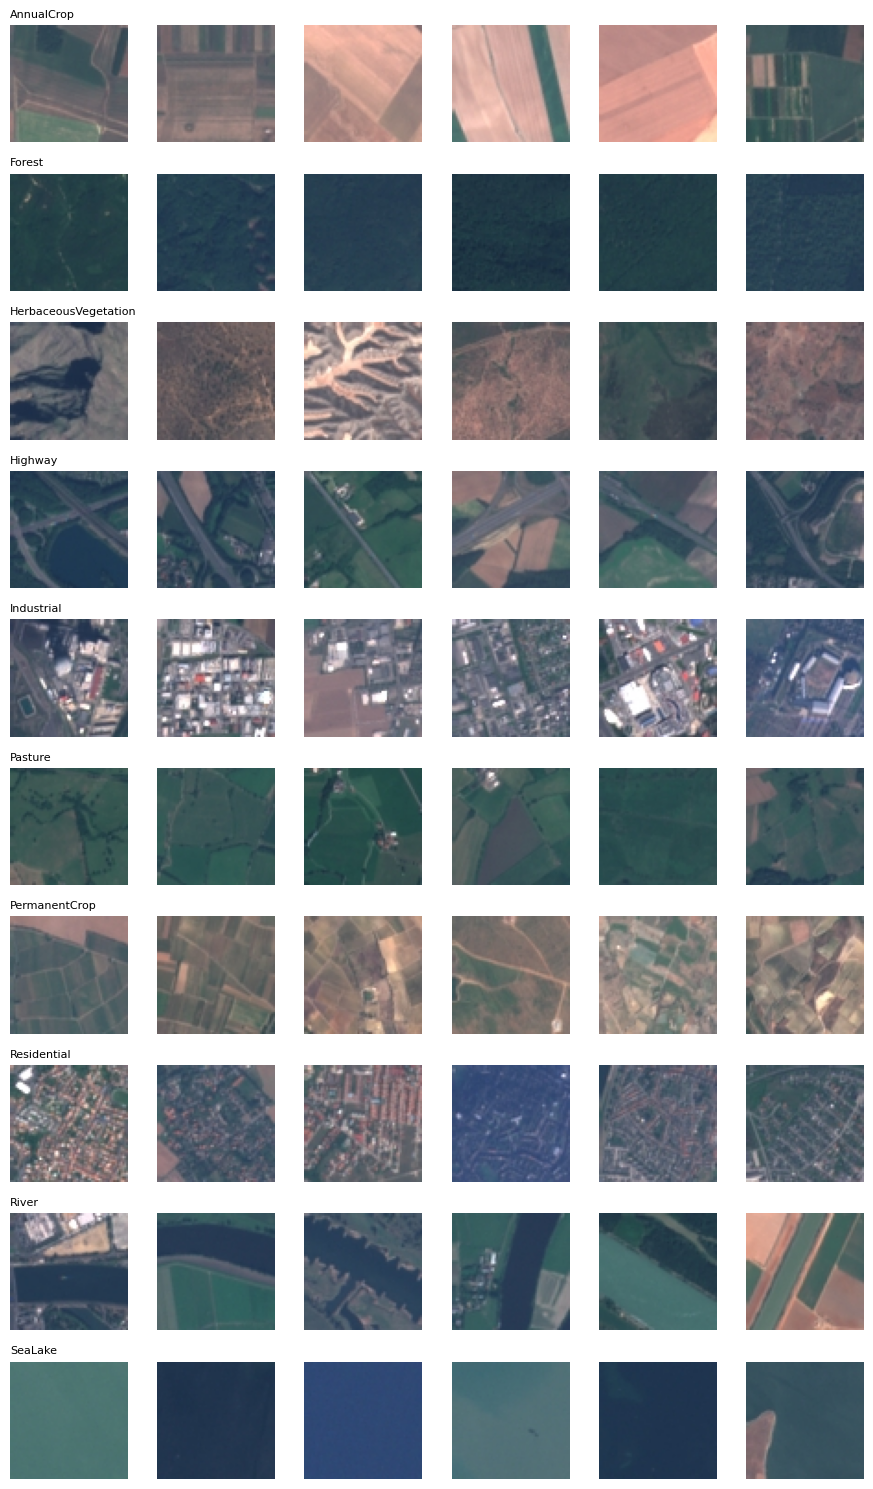

In [9]:
# Recorremos cada partición una vez para obtener las etiquetas (y algunas imágenes de ejemplo / las de test)
y_train, ejemplos = [], {}
for im, lb in tfds.as_numpy(ds_train_raw):
    y_train.append(lb)
    if len(ejemplos.setdefault(int(lb), [])) < 6:
        ejemplos[int(lb)].append(im)
y_train = np.array(y_train)
y_val = np.array([lb for _, lb in tfds.as_numpy(ds_val_raw)])
X_test, y_test = [], []
for im, lb in tfds.as_numpy(ds_test_raw):
    X_test.append(im); y_test.append(lb)
X_test, y_test = np.stack(X_test), np.array(y_test)

print(f"train: {len(y_train)} | val: {len(y_val)} | test: {len(y_test)} | forma de una imagen: {X_test[0].shape}, {X_test[0].dtype}")
assert X_test.shape[1:] == (64, 64, 3) and NUM_CLASSES == 10

prop = pd.DataFrame({'train': np.bincount(y_train, minlength=NUM_CLASSES) / len(y_train),
                     'val':   np.bincount(y_val,   minlength=NUM_CLASSES) / len(y_val),
                     'test':  np.bincount(y_test,  minlength=NUM_CLASSES) / len(y_test)}, index=class_names).round(3)
print("\nProporción de cada clase en cada partición:")
print(prop)

conteo = pd.Series(np.concatenate([y_train, y_val, y_test])).value_counts().sort_index()
conteo.index = [class_names[i] for i in conteo.index]
fig, ax = plt.subplots(figsize=(10, 4))
conteo.plot.bar(ax=ax, color="steelblue"); ax.set_title("Imágenes por clase (dataset completo)"); ax.set_ylabel("nº imágenes")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(NUM_CLASSES, 6, figsize=(9, 15))
for c in range(NUM_CLASSES):
    for j, im in enumerate(ejemplos[c]):
        axes[c, j].imshow(im); axes[c, j].axis("off")
    axes[c, 0].set_title(class_names[c], fontsize=8, loc="left")
plt.tight_layout(); plt.show()

**Observaciones.** Las clases están ligeramente desbalanceadas (entre 2 000 y 3 000 imágenes). La partición por porcentajes de TFDS no es estratificada, pero como TFDS guarda los ejemplos mezclados, la tabla de proporciones muestra que cada clase aparece con una proporción muy similar en train, validación y test. Algunas clases son visualmente muy parecidas (p. ej. *Highway* y *River*, *Pasture* y *PermanentCrop*, *Residential* e *Industrial*), lo que anticipa confusiones que una red densa tendrá difícil resolver.

## 3. Preprocesado

Sobre cada partición (con `map`, como se hace con `tf.data`) se aplican:

1. **Normalización** de los píxeles de [0, 255] a [0, 1] (dividir entre 255).
2. **Aplanado** de cada imagen 64×64×3 a un vector de 12 288 valores.
3. **One-hot** de las etiquetas (10 clases) para usar `categorical_crossentropy`.

Después se agrupan en lotes de 128 (`batch`), igual que en el ejercicio del Lab 4. El conjunto de entrenamiento se mezcla en cada época (`shuffle`).

In [10]:
INPUT_DIM = 64 * 64 * 3

def preprocesar(imagen, etiqueta):
    imagen = tf.cast(imagen, tf.float32) / 255.0      # 1) normalización a [0,1]
    imagen = tf.reshape(imagen, [INPUT_DIM])          # 2) aplanado -> (12288,)
    etiqueta = tf.one_hot(etiqueta, NUM_CLASSES)      # 3) one-hot
    return imagen, etiqueta

ds_train = (ds_train_raw.shuffle(len(y_train), seed=seed)
            .map(preprocesar).batch(TAM_LOTE).prefetch(tf.data.AUTOTUNE))
ds_val   = ds_val_raw.map(preprocesar).batch(TAM_LOTE).prefetch(tf.data.AUTOTUNE)
ds_test  = ds_test_raw.map(preprocesar).batch(TAM_LOTE).prefetch(tf.data.AUTOTUNE)

# Comprobación de un lote
for x, y in ds_train.take(1):
    print("lote de imágenes:", x.shape, "| lote de etiquetas:", y.shape)
    print("rango de valores: [%.2f, %.2f]" % (x.numpy().min(), x.numpy().max()))
    print("ejemplo one-hot:", y[0].numpy())

lote de imágenes: (128, 12288) | lote de etiquetas: (128, 10)
rango de valores: [0.08, 1.00]
ejemplo one-hot: [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]


## 4. Funciones auxiliares

- `plot(history)`: la misma función de los laboratorios para dibujar accuracy y loss de entrenamiento y validación.
- `crear_modelo(...)`: crea un `Sequential` con el mismo patrón de los laboratorios (`layers.Input` + capas `Dense`), con L2 (`kernel_regularizer`), `Dropout` entre capas y `BatchNormalization` después de la capa densa, de forma parametrizable.
- `entrenar(...)`: compila, entrena (`fit` con `validation_data`), dibuja la gráfica y guarda las métricas (`evaluate`) en una tabla de resultados.

Todos los modelos se entrenan con las mismas particiones, el mismo tamaño de lote y la misma semilla.

In [11]:
NUM_EPOCHS = 100
RESULTS = {}
MODELS = {}
HISTORIES = {}

def plot(history):
    accuracy = history.history["accuracy"]
    val_accuracy = history.history["val_accuracy"]
    loss = history.history["loss"]
    val_loss = history.history["val_loss"]

    epochs = range(1, len(accuracy) + 1)

    plt.plot(epochs, accuracy, "b-o", label="Training accuracy")
    plt.plot(epochs, val_accuracy, "r--o", label="Validation accuracy")
    plt.title("Training and validation accuracy")
    plt.legend()
    plt.figure()

    plt.plot(epochs, loss, "b-o", label="Training loss")
    plt.plot(epochs, val_loss, "r--o", label="Validation loss")
    plt.title("Training and validation loss")
    plt.legend()
    plt.show()

def crear_modelo(hidden=(512, 256), l2=0.0, dropout=0.0, batchnorm=False, initializer='glorot_uniform', name='mlp'):
    fijar_semilla()
    model = keras.Sequential(name=name)
    model.add(layers.Input(shape=(INPUT_DIM,)))
    reg = regularizers.l2(l2) if l2 > 0 else None
    for i, units in enumerate(hidden, start=1):
        model.add(layers.Dense(units, name=f'hidden_{i}', activation='relu',
                               kernel_regularizer=reg, kernel_initializer=initializer))
        if batchnorm:
            model.add(layers.BatchNormalization())
        if dropout > 0:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(NUM_CLASSES, name='output', activation='softmax'))
    return model

def registrar(nombre, model, history):
    tr = model.evaluate(ds_train, verbose=0, return_dict=True)
    va = model.evaluate(ds_val,   verbose=0, return_dict=True)
    te = model.evaluate(ds_test,  verbose=0, return_dict=True)
    RESULTS[nombre] = dict(modelo=nombre, params=model.count_params(), epocas=len(history.history['loss']),
                           train_acc=tr['accuracy'], val_acc=va['accuracy'], test_acc=te['accuracy'],
                           gap_train_val=tr['accuracy'] - va['accuracy'], val_loss=va['loss'])
    MODELS[nombre] = model
    HISTORIES[nombre] = history.history
    r = RESULTS[nombre]
    print(f"[{nombre}] épocas={r['epocas']} | train={r['train_acc']:.4f} | val={r['val_acc']:.4f} | "
          f"test={r['test_acc']:.4f} | gap(train-val)={r['gap_train_val']:.4f}")

def entrenar(nombre, model, optimizer='adam', early_stopping=False, patience=10, epochs=NUM_EPOCHS):
    model.compile(optimizer=optimizer,
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    callbacks = []
    if early_stopping:
        callbacks.append(EarlyStopping(monitor='val_loss', mode='min', patience=patience, restore_best_weights=True))
    history = model.fit(ds_train, epochs=epochs, validation_data=ds_val, callbacks=callbacks, verbose=2)
    plot(history)
    registrar(nombre, model, history)
    return history

## 5. Modelo base (sin regularización)

Arquitectura inicial para un MLP sobre 12 288 entradas (el tamaño 512-256 se ha elegido como punto de partida estándar y **no se ha optimizado**; los laboratorios usan redes más pequeñas porque sus entradas son mucho menos numerosas): dos capas ocultas (512 y 256 neuronas) con ReLU y salida softmax de 10 neuronas. Optimizador **Adam** con sus parámetros por defecto y entrenamiento de hasta 100 épocas **sin** ninguna regularización, para observar el sobreaprendizaje.

In [12]:
# Modelo base, definido capa a capa como en los laboratorios
fijar_semilla()
model = keras.Sequential(name='base')
model.add(layers.Input(shape=(INPUT_DIM,)))
model.add(layers.Dense(512, name='hidden_1', activation='relu'))
model.add(layers.Dense(256, name='hidden_2', activation='relu'))
model.add(layers.Dense(NUM_CLASSES, name='output', activation='softmax'))

model.summary()

Model: "base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_1 (Dense)                │ (None, 512)            │     6,291,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,425,866 (24.51 MB)

 Trainable params: 6,425,866 (24.51 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
148/148 - 8s - 56ms/step - accuracy: 0.2657 - loss: 2.3939 - val_accuracy: 0.3316 - val_loss: 1.7445
Epoch 2/100
148/148 - 1s - 7ms/step - accuracy: 0.3703 - loss: 1.6745 - val_accuracy: 0.3662 - val_loss: 1.6928
Epoch 3/100
148/148 - 1s - 8ms/step - accuracy: 0.4131 - loss: 1.5789 - val_accuracy: 0.4227 - val_loss: 1.5485
Epoch 4/100
148/148 - 1s - 7ms/step - accuracy: 0.4294 - loss: 1.5377 - val_accuracy: 0.3948 - val_loss: 1.5577
Epoch 5/100
148/148 - 1s - 7ms/step - accuracy: 0.4448 - loss: 1.4974 - val_accuracy: 0.4220 - val_loss: 1.5298
Epoch 6/100
148/148 - 1s - 9ms/step - accuracy: 0.4652 - loss: 1.4563 - val_accuracy: 0.4677 - val_loss: 1.4714
Epoch 7/100
148/148 - 1s - 9ms/step - accuracy: 0.4816 - loss: 1.4197 - val_accuracy: 0.4790 - val_loss: 1.3928
Epoch 8/100
148/148 - 1s - 8ms/step - accuracy: 0.4949 - loss: 1.3802 - val_accuracy: 0.4568 - val_loss: 1.4493
Epoch 9/100
148/148 - 2s - 16ms/step - accuracy: 0.5029 - loss: 1.3713 - val_accuracy: 0.5175 - val_los

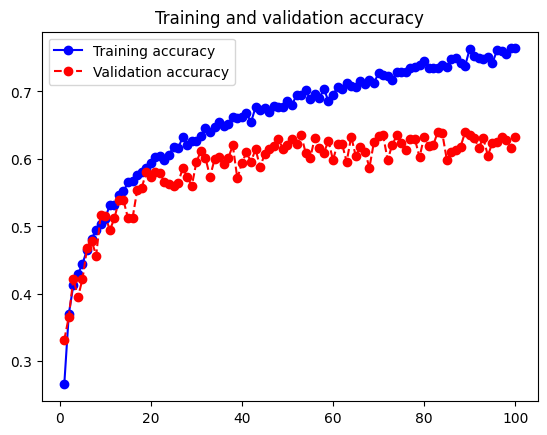

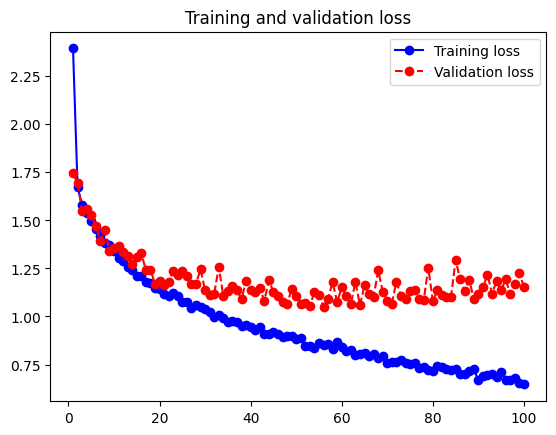

[M1 Base (512-256)] épocas=100 | train=0.7774 | val=0.6323 | test=0.6360 | gap(train-val)=0.1450
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6360 - loss: 1.1329
['loss', 'compile_metrics']
[1.1328576803207397, 0.6360493898391724]


In [13]:
history = entrenar('M1 Base (512-256)', model)
results = model.evaluate(ds_test)
print(model.metrics_names)
print(results)

**Comentario M1.** El modelo base sobreajusta: la accuracy de entrenamiento sigue subiendo (≈ 0.78 al final) mientras que la de validación se estanca (≈ 0.63) y la *loss* de validación toca su mínimo hacia la época 56 (≈ 1.05) y después crece (≈ 1.16 en la época 100). Es la memorización esperable con más de 6 M de parámetros frente a 18 900 imágenes. La diferencia train-val (`gap_train_val`, ≈ 14.5 puntos) cuantifica el sobreaprendizaje y es la métrica que intentaremos reducir con la regularización. La accuracy de validación oscila bastante entre épocas (±3 puntos), por lo que las diferencias de uno o dos puntos entre modelos hay que interpretarlas con cautela (cada modelo se entrena con una sola semilla).

> **Decisión tomada tras una primera ejecución (problemas encontrados).** En una primera ejecución con solo 30 épocas el modelo base **no llegaba a sobreajustar**: la *loss* de validación seguía bajando en la última época, la accuracy de validación seguía subiendo y el gap train-val era de solo ≈ 5 puntos. Con ese horizonte no hay sobreaprendizaje que corregir y las técnicas de regularización solo podían empeorar o dejar igual el resultado. Por eso se amplió el entrenamiento a **100 épocas** (con paciencia 10 en Early Stopping), para que el modelo base tenga tiempo de memorizar y se pueda medir el efecto real de cada regularización.

## 6. Técnicas de regularización (una a una)

Se parte del modelo base y se añade **una sola** técnica cada vez para poder aislar su efecto.

### 6.1 Regularización L2 (weight decay)
Se añade `kernel_regularizer=regularizers.l2(alpha)` a las capas densas (como en el Lab 4), que penaliza los pesos grandes. Probamos tres valores de `alpha`.

Epoch 1/100
148/148 - 5s - 36ms/step - accuracy: 0.2587 - loss: 2.3745 - val_accuracy: 0.3114 - val_loss: 1.9005
Epoch 2/100
148/148 - 2s - 14ms/step - accuracy: 0.3703 - loss: 1.6954 - val_accuracy: 0.3753 - val_loss: 1.6717
Epoch 3/100
148/148 - 2s - 11ms/step - accuracy: 0.4072 - loss: 1.5963 - val_accuracy: 0.4462 - val_loss: 1.5213
Epoch 4/100
148/148 - 1s - 7ms/step - accuracy: 0.4363 - loss: 1.5338 - val_accuracy: 0.4151 - val_loss: 1.5469
Epoch 5/100
148/148 - 1s - 7ms/step - accuracy: 0.4530 - loss: 1.4905 - val_accuracy: 0.4074 - val_loss: 1.5926
Epoch 6/100
148/148 - 1s - 7ms/step - accuracy: 0.4542 - loss: 1.4927 - val_accuracy: 0.4558 - val_loss: 1.4994
Epoch 7/100
148/148 - 1s - 7ms/step - accuracy: 0.4765 - loss: 1.4407 - val_accuracy: 0.4751 - val_loss: 1.4517
Epoch 8/100
148/148 - 1s - 7ms/step - accuracy: 0.4959 - loss: 1.4064 - val_accuracy: 0.4719 - val_loss: 1.4226
Epoch 9/100
148/148 - 1s - 9ms/step - accuracy: 0.5139 - loss: 1.3583 - val_accuracy: 0.5079 - val_lo

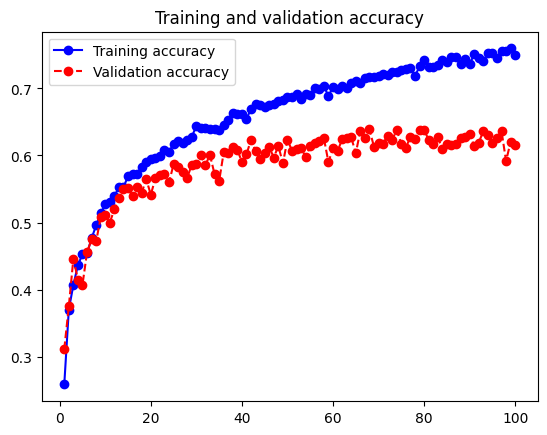

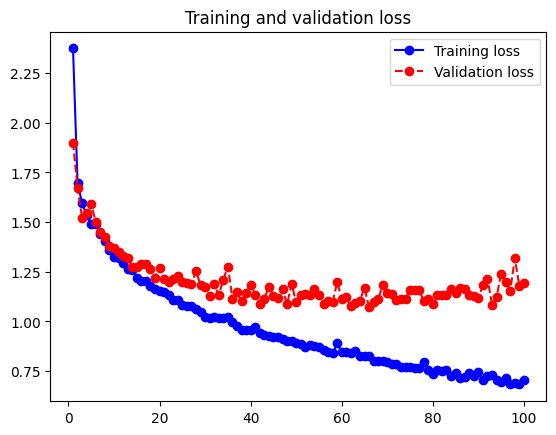

[M2 L2 alpha=1e-05] épocas=100 | train=0.7279 | val=0.6153 | test=0.6143 | gap(train-val)=0.1126
Epoch 1/100
148/148 - 5s - 36ms/step - accuracy: 0.2601 - loss: 2.4960 - val_accuracy: 0.3607 - val_loss: 1.8018
Epoch 2/100
148/148 - 1s - 8ms/step - accuracy: 0.3703 - loss: 1.7518 - val_accuracy: 0.4017 - val_loss: 1.7007
Epoch 3/100
148/148 - 1s - 8ms/step - accuracy: 0.4144 - loss: 1.6446 - val_accuracy: 0.4232 - val_loss: 1.6088
Epoch 4/100
148/148 - 1s - 8ms/step - accuracy: 0.4316 - loss: 1.5948 - val_accuracy: 0.4277 - val_loss: 1.5738
Epoch 5/100
148/148 - 1s - 8ms/step - accuracy: 0.4421 - loss: 1.5554 - val_accuracy: 0.3998 - val_loss: 1.6640
Epoch 6/100
148/148 - 1s - 7ms/step - accuracy: 0.4589 - loss: 1.5229 - val_accuracy: 0.4178 - val_loss: 1.5536
Epoch 7/100
148/148 - 1s - 7ms/step - accuracy: 0.4697 - loss: 1.4923 - val_accuracy: 0.4622 - val_loss: 1.4821
Epoch 8/100
148/148 - 2s - 12ms/step - accuracy: 0.4887 - loss: 1.4547 - val_accuracy: 0.4919 - val_loss: 1.4301
Epoch

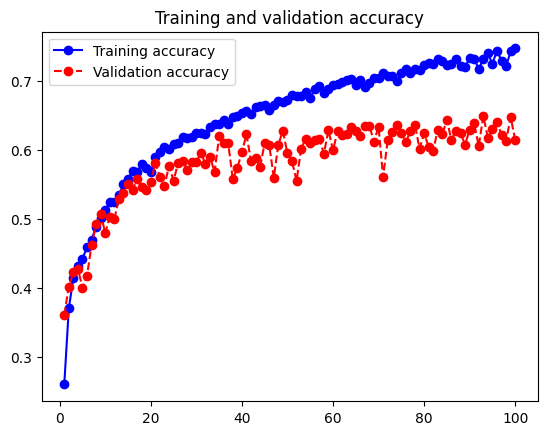

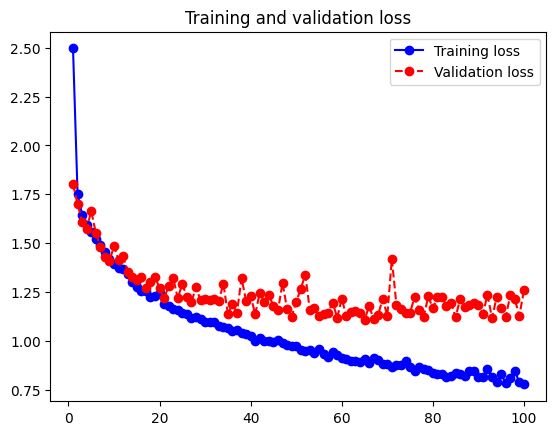

[M2 L2 alpha=0.0001] épocas=100 | train=0.7206 | val=0.6143 | test=0.6126 | gap(train-val)=0.1063
Epoch 1/100
148/148 - 4s - 30ms/step - accuracy: 0.2594 - loss: 3.1409 - val_accuracy: 0.3393 - val_loss: 2.3575
Epoch 2/100
148/148 - 2s - 13ms/step - accuracy: 0.3451 - loss: 2.1883 - val_accuracy: 0.3795 - val_loss: 2.0654
Epoch 3/100
148/148 - 2s - 13ms/step - accuracy: 0.4006 - loss: 1.9521 - val_accuracy: 0.4030 - val_loss: 1.8843
Epoch 4/100
148/148 - 1s - 7ms/step - accuracy: 0.4211 - loss: 1.8158 - val_accuracy: 0.3933 - val_loss: 1.8446
Epoch 5/100
148/148 - 1s - 7ms/step - accuracy: 0.4298 - loss: 1.7341 - val_accuracy: 0.4417 - val_loss: 1.7056
Epoch 6/100
148/148 - 1s - 7ms/step - accuracy: 0.4430 - loss: 1.6747 - val_accuracy: 0.4373 - val_loss: 1.7133
Epoch 7/100
148/148 - 1s - 8ms/step - accuracy: 0.4549 - loss: 1.6344 - val_accuracy: 0.4694 - val_loss: 1.6199
Epoch 8/100
148/148 - 1s - 8ms/step - accuracy: 0.4700 - loss: 1.5859 - val_accuracy: 0.4635 - val_loss: 1.5698
Epo

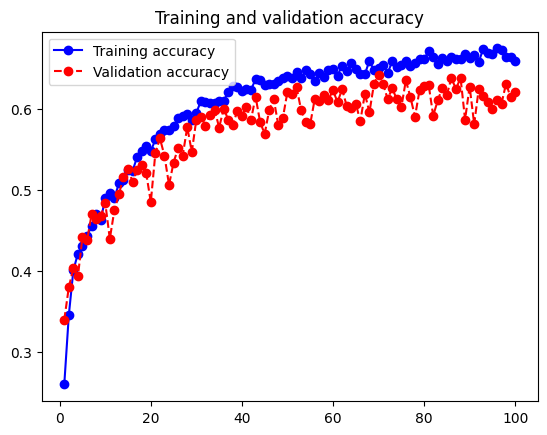

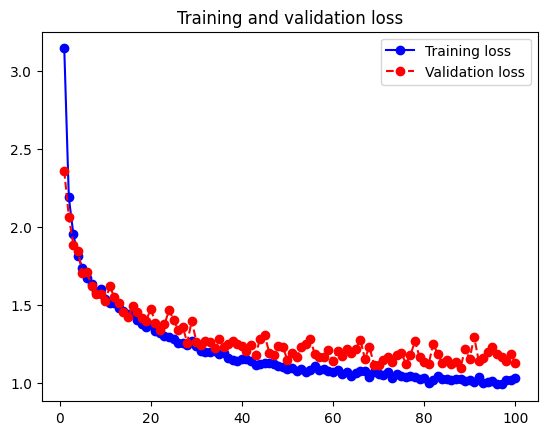

[M2 L2 alpha=0.001] épocas=100 | train=0.6878 | val=0.6212 | test=0.6378 | gap(train-val)=0.0666


In [14]:
for alpha in [1e-5, 1e-4, 1e-3]:
    model = crear_modelo(l2=alpha, name=f'l2_{alpha:g}')
    entrenar(f'M2 L2 alpha={alpha:g}', model)

**Comentario M2.** Con `alpha` = 1e-5 y 1e-4 el gap baja algo (de ≈ 14.5 a ≈ 11 puntos) pero la accuracy de validación y de test no mejora (≈ 0.61, ligeramente por debajo del base, dentro del ruido). Con `alpha` = 1e-3 el gap baja a menos de la mitad (≈ 6.7 puntos) y la accuracy de test se mantiene (≈ 0.64 frente a ≈ 0.64 del base), aunque la de validación baja un punto (0.621 frente a 0.632, diferencia dentro del ruido). L2 reduce el sobreaprendizaje sin coste apreciable en accuracy, pero tampoco la mejora; `alpha` = 1e-3 es el valor que usaremos más adelante.

### 6.2 Dropout
Se añaden capas `Dropout` entre las capas densas (Lab 4), que apagan aleatoriamente un porcentaje de neuronas en cada paso de entrenamiento. Probamos tasas de 0.1 y 0.3.

Epoch 1/100
148/148 - 7s - 47ms/step - accuracy: 0.2556 - loss: 2.1934 - val_accuracy: 0.3854 - val_loss: 1.7232
Epoch 2/100
148/148 - 1s - 7ms/step - accuracy: 0.3437 - loss: 1.7098 - val_accuracy: 0.3894 - val_loss: 1.6403
Epoch 3/100
148/148 - 1s - 8ms/step - accuracy: 0.3879 - loss: 1.6181 - val_accuracy: 0.4244 - val_loss: 1.5291
Epoch 4/100
148/148 - 1s - 7ms/step - accuracy: 0.4001 - loss: 1.5821 - val_accuracy: 0.4368 - val_loss: 1.5153
Epoch 5/100
148/148 - 1s - 7ms/step - accuracy: 0.4185 - loss: 1.5443 - val_accuracy: 0.4647 - val_loss: 1.4711
Epoch 6/100
148/148 - 1s - 7ms/step - accuracy: 0.4299 - loss: 1.5187 - val_accuracy: 0.4398 - val_loss: 1.5116
Epoch 7/100
148/148 - 1s - 8ms/step - accuracy: 0.4487 - loss: 1.4820 - val_accuracy: 0.4911 - val_loss: 1.4254
Epoch 8/100
148/148 - 2s - 14ms/step - accuracy: 0.4567 - loss: 1.4615 - val_accuracy: 0.4815 - val_loss: 1.4108
Epoch 9/100
148/148 - 2s - 12ms/step - accuracy: 0.4652 - loss: 1.4457 - val_accuracy: 0.4931 - val_lo

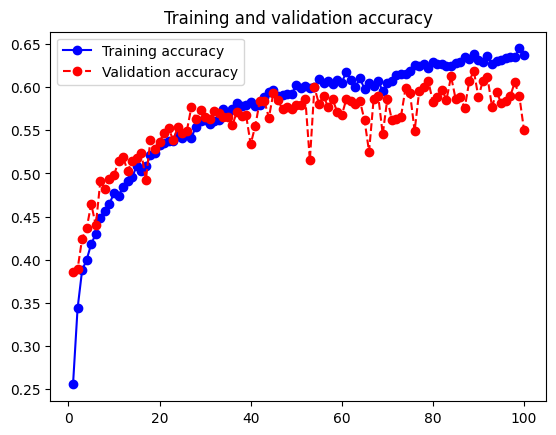

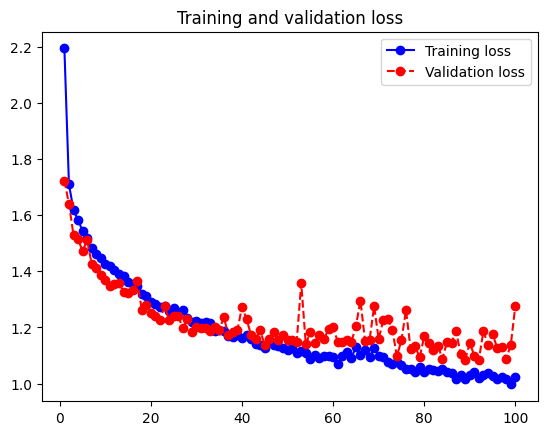

[M3 Dropout 0.1] épocas=100 | train=0.6234 | val=0.5509 | test=0.5575 | gap(train-val)=0.0725
Epoch 1/100
148/148 - 6s - 39ms/step - accuracy: 0.2133 - loss: 2.2411 - val_accuracy: 0.3817 - val_loss: 1.7893
Epoch 2/100
148/148 - 1s - 7ms/step - accuracy: 0.2934 - loss: 1.8179 - val_accuracy: 0.3817 - val_loss: 1.7032
Epoch 3/100
148/148 - 2s - 14ms/step - accuracy: 0.3054 - loss: 1.7908 - val_accuracy: 0.3738 - val_loss: 1.7215
Epoch 4/100
148/148 - 2s - 12ms/step - accuracy: 0.3012 - loss: 1.8222 - val_accuracy: 0.3995 - val_loss: 1.6584
Epoch 5/100
148/148 - 1s - 8ms/step - accuracy: 0.3116 - loss: 1.8021 - val_accuracy: 0.3763 - val_loss: 1.6739
Epoch 6/100
148/148 - 1s - 7ms/step - accuracy: 0.3063 - loss: 1.8095 - val_accuracy: 0.4086 - val_loss: 1.6498
Epoch 7/100
148/148 - 1s - 7ms/step - accuracy: 0.3181 - loss: 1.7804 - val_accuracy: 0.3919 - val_loss: 1.6325
Epoch 8/100
148/148 - 1s - 8ms/step - accuracy: 0.3199 - loss: 1.7803 - val_accuracy: 0.4091 - val_loss: 1.6373
Epoch 9

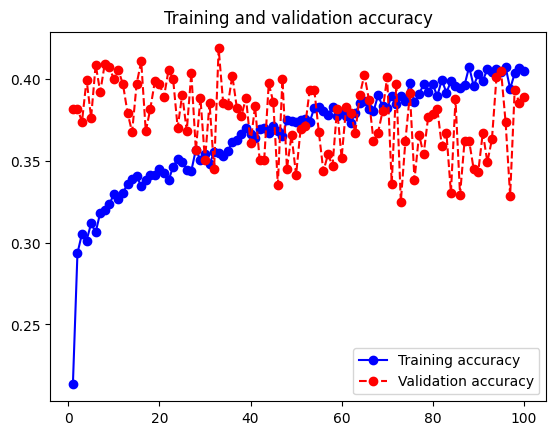

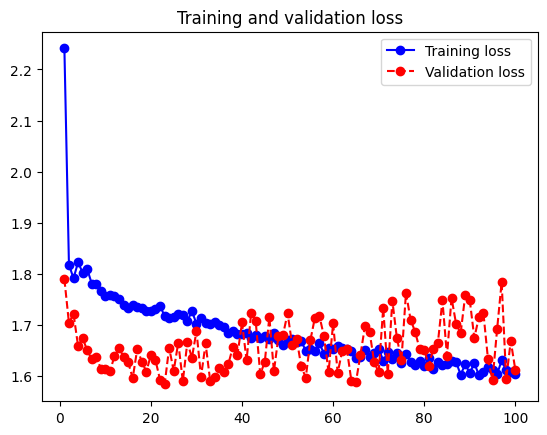

[M3 Dropout 0.3] épocas=100 | train=0.4051 | val=0.3889 | test=0.3872 | gap(train-val)=0.0162


In [15]:
for p in [0.1, 0.3]:
    model = crear_modelo(dropout=p, name=f'dropout_{p}')
    entrenar(f'M3 Dropout {p}', model)

**Comentario M3.** En esta red el dropout **empeora** el modelo en lugar de regularizarlo: con 0.1 la accuracy de validación baja a ≈ 0.55 y con 0.3 a ≈ 0.39 (frente a ≈ 0.63 del modelo base). El gap train-val es pequeño, pero porque el modelo no llega a aprender: la accuracy de entrenamiento también cae (≈ 0.62 y ≈ 0.41, *underfitting*). Una posible explicación (no comprobada) es que la imagen aplanada es muy redundante y apagar neuronas añade mucho ruido a un entrenamiento que ya converge despacio. Es un resultado negativo que descarta el dropout para este problema.

### 6.3 Batch Normalization
Como en el Lab 5, se añade una capa `BatchNormalization` después de cada capa densa.

Epoch 1/100
148/148 - 7s - 49ms/step - accuracy: 0.5143 - loss: 1.4003 - val_accuracy: 0.2489 - val_loss: 2.2302
Epoch 2/100
148/148 - 1s - 7ms/step - accuracy: 0.5947 - loss: 1.1674 - val_accuracy: 0.3652 - val_loss: 1.9644
Epoch 3/100
148/148 - 1s - 7ms/step - accuracy: 0.6228 - loss: 1.0847 - val_accuracy: 0.3511 - val_loss: 2.4261
Epoch 4/100
148/148 - 1s - 7ms/step - accuracy: 0.6350 - loss: 1.0483 - val_accuracy: 0.2822 - val_loss: 3.1697
Epoch 5/100
148/148 - 1s - 9ms/step - accuracy: 0.6453 - loss: 1.0107 - val_accuracy: 0.3748 - val_loss: 2.1805
Epoch 6/100
148/148 - 1s - 7ms/step - accuracy: 0.6622 - loss: 0.9678 - val_accuracy: 0.3679 - val_loss: 2.4699
Epoch 7/100
148/148 - 1s - 7ms/step - accuracy: 0.6723 - loss: 0.9388 - val_accuracy: 0.2798 - val_loss: 3.9695
Epoch 8/100
148/148 - 2s - 16ms/step - accuracy: 0.6875 - loss: 0.8984 - val_accuracy: 0.3664 - val_loss: 3.0172
Epoch 9/100
148/148 - 2s - 11ms/step - accuracy: 0.6882 - loss: 0.8798 - val_accuracy: 0.3047 - val_lo

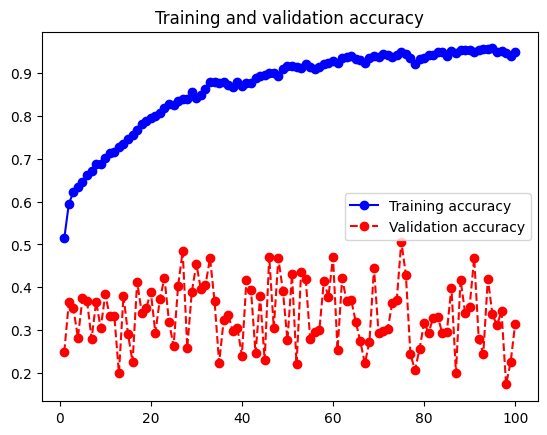

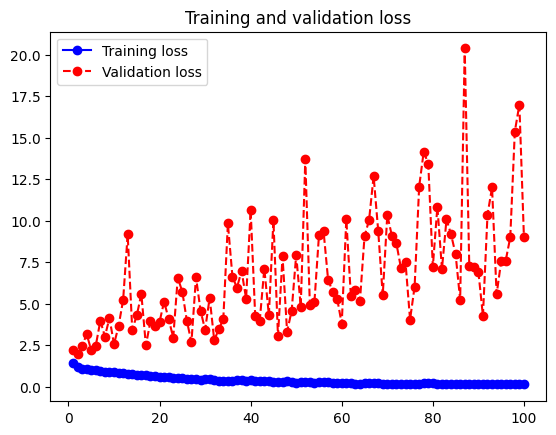

[M4 BatchNorm] épocas=100 | train=0.4216 | val=0.3151 | test=0.3185 | gap(train-val)=0.1065


In [16]:
model = crear_modelo(batchnorm=True, name='batchnorm')
entrenar('M4 BatchNorm', model)

**Comentario M4.** BatchNorm no funciona en esta configuración. En las curvas, la accuracy de entrenamiento (calculada durante el `fit`, con estadísticas del lote) llega a ≈ 0.95, mientras que la de validación oscila entre 0.2 y 0.5 sin estabilizarse, con una *loss* de validación muy inestable. Además, al volver a evaluar el conjunto de entrenamiento en modo inferencia (tabla de resultados) la accuracy cae a ≈ 0.42 (val ≈ 0.32, test ≈ 0.32). Esto indica una discrepancia entre el modo de entrenamiento (estadísticas del lote) y el de inferencia (estadísticas móviles). Se probó en una ejecución previa bajar el *learning rate* a 1e-4 por si la causa era que los pesos cambian demasiado rápido para las estadísticas móviles, pero no solucionó el problema (empeoró). No se ha investigado más la causa; queda como resultado negativo y se descarta BatchNorm en los experimentos siguientes.

### 6.4 Early Stopping
Callback `EarlyStopping` del Lab 4 (`monitor='val_loss'`, `mode='min'`), con paciencia de 10 épocas (mayor que la de 3 del laboratorio porque con 12 288 entradas la validación es muy ruidosa y con paciencias cortas se detenía demasiado pronto) y `restore_best_weights=True` para quedarnos con los mejores pesos.

Epoch 1/100
148/148 - 5s - 31ms/step - accuracy: 0.2548 - loss: 2.3387 - val_accuracy: 0.2746 - val_loss: 1.8637
Epoch 2/100
148/148 - 2s - 14ms/step - accuracy: 0.3638 - loss: 1.6738 - val_accuracy: 0.3706 - val_loss: 1.6387
Epoch 3/100
148/148 - 1s - 7ms/step - accuracy: 0.4137 - loss: 1.5759 - val_accuracy: 0.4351 - val_loss: 1.6004
Epoch 4/100
148/148 - 1s - 9ms/step - accuracy: 0.4395 - loss: 1.5169 - val_accuracy: 0.3909 - val_loss: 1.5973
Epoch 5/100
148/148 - 1s - 8ms/step - accuracy: 0.4426 - loss: 1.5101 - val_accuracy: 0.4459 - val_loss: 1.5323
Epoch 6/100
148/148 - 1s - 7ms/step - accuracy: 0.4672 - loss: 1.4610 - val_accuracy: 0.4706 - val_loss: 1.4817
Epoch 7/100
148/148 - 1s - 8ms/step - accuracy: 0.4856 - loss: 1.4217 - val_accuracy: 0.4588 - val_loss: 1.4620
Epoch 8/100
148/148 - 1s - 7ms/step - accuracy: 0.4935 - loss: 1.3972 - val_accuracy: 0.4914 - val_loss: 1.4164
Epoch 9/100
148/148 - 1s - 9ms/step - accuracy: 0.5016 - loss: 1.3726 - val_accuracy: 0.4931 - val_los

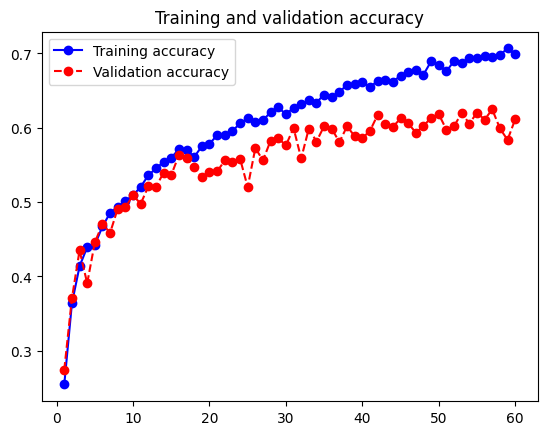

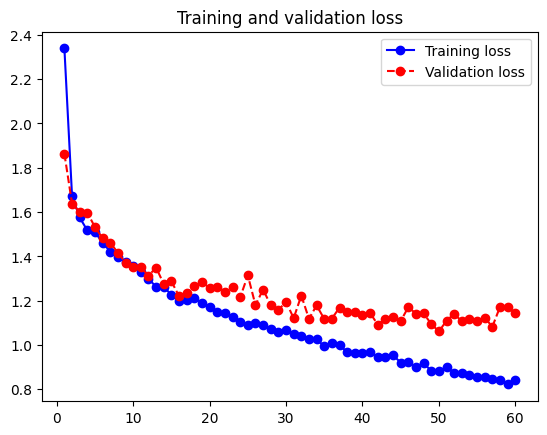

[M5 Early Stopping] épocas=60 | train=0.7116 | val=0.6183 | test=0.6304 | gap(train-val)=0.0934


In [17]:
model = crear_modelo(name='early_stopping')
entrenar('M5 Early Stopping', model, early_stopping=True)

**Comentario M5.** Early Stopping detiene el entrenamiento en la época 60 (la mejor *val_loss* fue en la época 50) y restaura esos pesos, así que usa 40 épocas menos que el modelo base. Su accuracy de validación (≈ 0.62) y de test (≈ 0.63) es prácticamente la misma que la del modelo base (0.632 y 0.636): no mejora la accuracy, pero llega a ella con menos cómputo. El gap train-val baja algo (≈ 9 puntos frente a ≈ 14.5) porque se interrumpe antes de memorizar más, pero sigue siendo alto: no regulariza el modelo, solo elige el momento en que generaliza mejor. El techo de rendimiento lo marca la arquitectura.

## 7. Modelo combinado

Combinamos las técnicas que no han empeorado el modelo: **L2 (alpha = 1e-3, el valor que mejor reduce el gap en 6.1) + Early Stopping**. No se incluyen Dropout ni BatchNorm porque en 6.2 y 6.3 empeoraron el modelo.

Epoch 1/100
148/148 - 5s - 31ms/step - accuracy: 0.2587 - loss: 3.1027 - val_accuracy: 0.3805 - val_loss: 2.2654
Epoch 2/100
148/148 - 1s - 7ms/step - accuracy: 0.3615 - loss: 2.1389 - val_accuracy: 0.3672 - val_loss: 2.0598
Epoch 3/100
148/148 - 1s - 9ms/step - accuracy: 0.4073 - loss: 1.9219 - val_accuracy: 0.4207 - val_loss: 1.8659
Epoch 4/100
148/148 - 1s - 8ms/step - accuracy: 0.4266 - loss: 1.7903 - val_accuracy: 0.4363 - val_loss: 1.7616
Epoch 5/100
148/148 - 2s - 11ms/step - accuracy: 0.4294 - loss: 1.7356 - val_accuracy: 0.4207 - val_loss: 1.7172
Epoch 6/100
148/148 - 2s - 14ms/step - accuracy: 0.4440 - loss: 1.6717 - val_accuracy: 0.4548 - val_loss: 1.6453
Epoch 7/100
148/148 - 1s - 7ms/step - accuracy: 0.4571 - loss: 1.6274 - val_accuracy: 0.4701 - val_loss: 1.6035
Epoch 8/100
148/148 - 1s - 8ms/step - accuracy: 0.4716 - loss: 1.5873 - val_accuracy: 0.4519 - val_loss: 1.6377
Epoch 9/100
148/148 - 1s - 8ms/step - accuracy: 0.4746 - loss: 1.5841 - val_accuracy: 0.4558 - val_lo

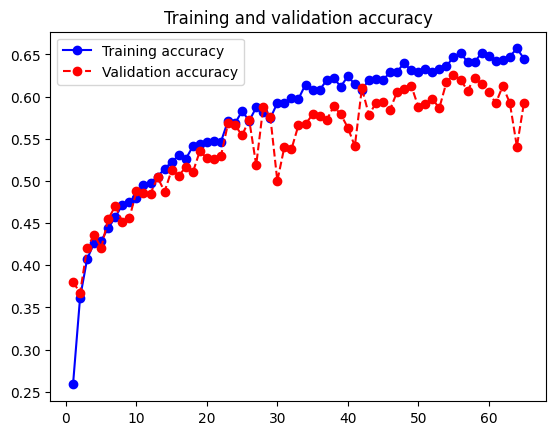

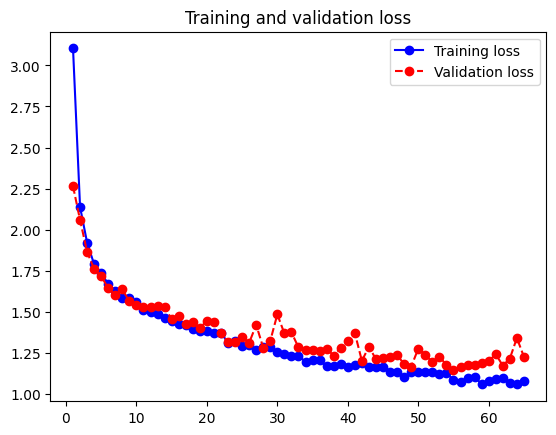

[M6 Combinado (L2 1e-3 + ES)] épocas=65 | train=0.6750 | val=0.6262 | test=0.6326 | gap(train-val)=0.0489


In [18]:
model = crear_modelo(l2=1e-3, name='combinado')
entrenar('M6 Combinado (L2 1e-3 + ES)', model, early_stopping=True)

**Comentario M6.** La combinación L2 + Early Stopping se detiene en la época 65 (mejor *val_loss* en la 55) y obtiene val ≈ 0.626 y test ≈ 0.633, es decir, la misma accuracy que el modelo base (0.632 / 0.636) y que cada técnica por separado (M2 con alpha = 1e-3: 0.621 / 0.638; M5: 0.618 / 0.630). Lo que cambia es el sobreaprendizaje: el gap train-val baja a ≈ 4.9 puntos, frente a ≈ 14.5 del base, ≈ 6.7 de L2 solo y ≈ 9.3 de Early Stopping solo. Es el modelo que menos sobreajusta entre los que aprenden bien, con menos épocas que el base, aunque no mejora la accuracy.

## 8. Optimización: optimizadores

Con la configuración combinada M6 (L2 1e-3 + Early Stopping), que usa Adam con sus parámetros por defecto (lr = 1e-3), probamos otros dos optimizadores del Lab 5, pasados por nombre (parámetros por defecto): `SGD` y `RMSprop`.

Epoch 1/100
148/148 - 4s - 25ms/step - accuracy: 0.2665 - loss: 3.2877 - val_accuracy: 0.2333 - val_loss: 3.2026
Epoch 2/100
148/148 - 1s - 7ms/step - accuracy: 0.3531 - loss: 3.0641 - val_accuracy: 0.3807 - val_loss: 3.0737
Epoch 3/100
148/148 - 1s - 9ms/step - accuracy: 0.3847 - loss: 2.9942 - val_accuracy: 0.3815 - val_loss: 2.9888
Epoch 4/100
148/148 - 1s - 8ms/step - accuracy: 0.4056 - loss: 2.9375 - val_accuracy: 0.4610 - val_loss: 2.9213
Epoch 5/100
148/148 - 2s - 16ms/step - accuracy: 0.4188 - loss: 2.8976 - val_accuracy: 0.4341 - val_loss: 2.8793
Epoch 6/100
148/148 - 1s - 7ms/step - accuracy: 0.4355 - loss: 2.8576 - val_accuracy: 0.4126 - val_loss: 2.8501
Epoch 7/100
148/148 - 1s - 9ms/step - accuracy: 0.4447 - loss: 2.8235 - val_accuracy: 0.4007 - val_loss: 2.8613
Epoch 8/100
148/148 - 1s - 8ms/step - accuracy: 0.4525 - loss: 2.7950 - val_accuracy: 0.4575 - val_loss: 2.7768
Epoch 9/100
148/148 - 1s - 7ms/step - accuracy: 0.4683 - loss: 2.7605 - val_accuracy: 0.4252 - val_los

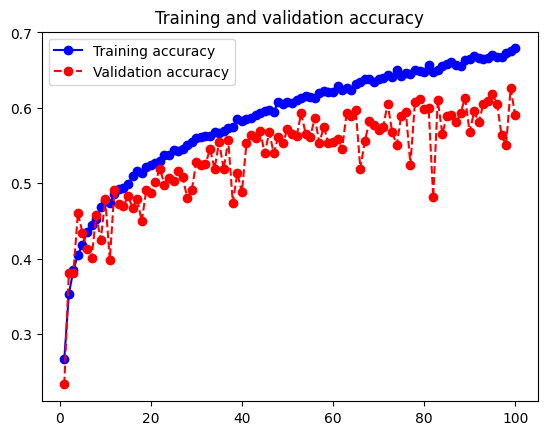

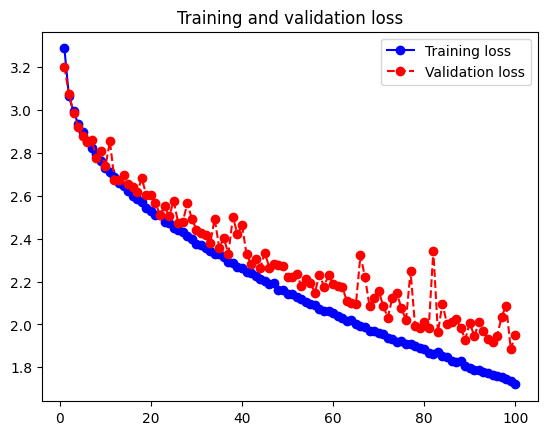

[M7 SGD (L2 1e-3 + ES)] épocas=100 | train=0.6979 | val=0.6257 | test=0.6291 | gap(train-val)=0.0722
Epoch 1/100
148/148 - 6s - 42ms/step - accuracy: 0.1939 - loss: 4.2186 - val_accuracy: 0.2249 - val_loss: 2.4044
Epoch 2/100
148/148 - 1s - 7ms/step - accuracy: 0.2889 - loss: 2.0345 - val_accuracy: 0.3230 - val_loss: 1.8728
Epoch 3/100
148/148 - 1s - 8ms/step - accuracy: 0.3431 - loss: 1.7998 - val_accuracy: 0.3069 - val_loss: 1.8980
Epoch 4/100
148/148 - 1s - 8ms/step - accuracy: 0.3670 - loss: 1.7319 - val_accuracy: 0.4358 - val_loss: 1.5892
Epoch 5/100
148/148 - 1s - 7ms/step - accuracy: 0.3870 - loss: 1.6826 - val_accuracy: 0.4323 - val_loss: 1.6315
Epoch 6/100
148/148 - 1s - 7ms/step - accuracy: 0.3987 - loss: 1.6543 - val_accuracy: 0.3593 - val_loss: 1.8467
Epoch 7/100
148/148 - 1s - 7ms/step - accuracy: 0.4085 - loss: 1.6327 - val_accuracy: 0.3731 - val_loss: 1.7084
Epoch 8/100
148/148 - 1s - 8ms/step - accuracy: 0.4125 - loss: 1.6263 - val_accuracy: 0.3995 - val_loss: 1.6446
Ep

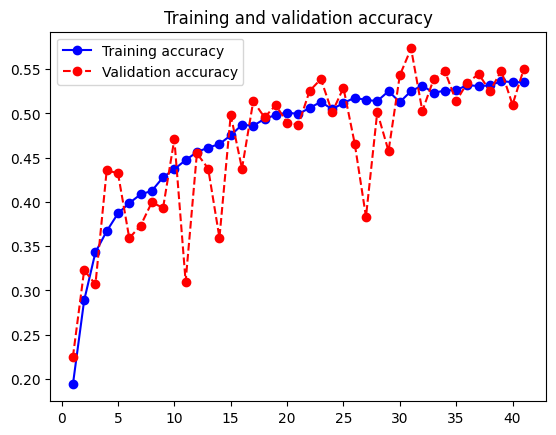

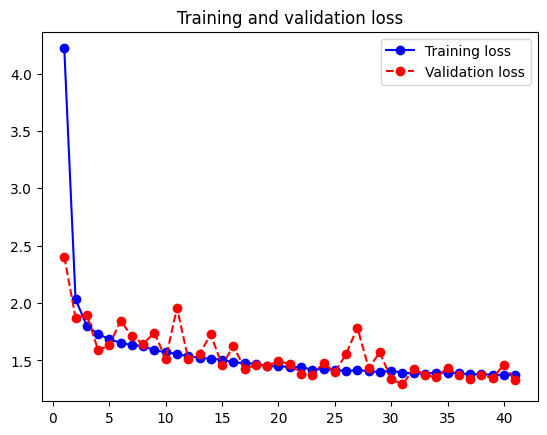

[M7 RMSprop (L2 1e-3 + ES)] épocas=41 | train=0.5908 | val=0.5733 | test=0.5736 | gap(train-val)=0.0175


In [19]:
for nombre in ['SGD', 'RMSprop']:
    model = crear_modelo(l2=1e-3, name=nombre.lower())
    entrenar(f'M7 {nombre} (L2 1e-3 + ES)', model, optimizer=nombre, early_stopping=True)

**Comentario M7.** Con L2 1e-3 + Early Stopping y los parámetros por defecto de cada optimizador:
- **Adam (M6, referencia):** val ≈ 0.626, test ≈ 0.633, se detiene en la época 65.
- **SGD (lr = 0.01):** val ≈ 0.626, test ≈ 0.629, gap ≈ 7.2 puntos. Llega al mismo nivel que Adam, pero es más lento: no activó el Early Stopping y consumió las 100 épocas.
- **RMSprop (lr = 1e-3):** es el peor, con val ≈ 0.573 y test ≈ 0.574. Se detiene pronto (época 41, mejor *val_loss* en la 31) con una accuracy de entrenamiento baja (≈ 0.59). Una explicación posible (no comprobada) es que con ese *learning rate* oscila y no llega a converger bien.

Cambiar de optimizador no supera el techo de ≈ 0.63: Adam y SGD empatan en accuracy y se diferencian en velocidad.

## 9. Selección y evaluación final del mejor modelo

El mejor modelo se elige por **accuracy de validación**. Sobre él se analiza el test con más detalle: matriz de confusión y métricas por clase.

Mejor modelo según validación: M1 Base (512-256)
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6360 - loss: 1.1329
['loss', 'compile_metrics']
[1.1328576803207397, 0.6360493898391724]
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step

                       precision    recall  f1-score   support

          AnnualCrop      0.644     0.560     0.599       475
              Forest      0.881     0.833     0.856       490
HerbaceousVegetation      0.516     0.626     0.566       447
             Highway      0.420     0.332     0.371       398
          Industrial      0.787     0.764     0.776       373
             Pasture      0.632     0.655     0.643       296
       PermanentCrop      0.535     0.407     0.462       337
         Residential      0.580     0.643     0.610       456
               River      0.547     0.603     0.574       348
             SeaLake      0.738     0.863     0.795       430

            accuracy                          0.636      4050
           macro avg 

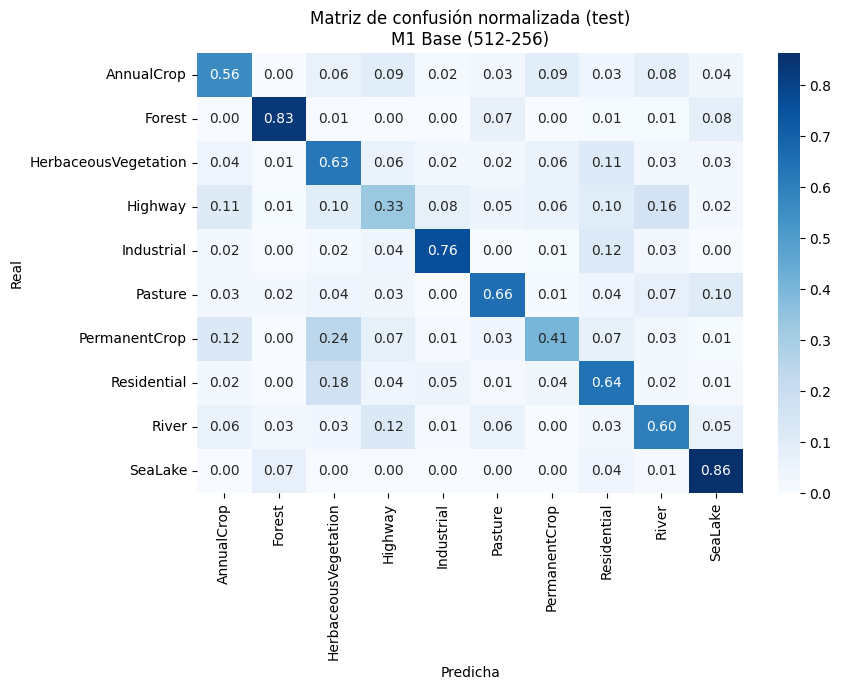

In [20]:
df = pd.DataFrame(RESULTS.values()).set_index("modelo")
mejor = df["val_acc"].idxmax()
print("Mejor modelo según validación:", mejor)
best_model = MODELS[mejor]

results = best_model.evaluate(ds_test)
print(best_model.metrics_names)
print(results)

y_pred = best_model.predict(ds_test).argmax(axis=1)     # ds_test no se mezcla, así que el orden coincide con y_test
print("\n", classification_report(y_test, y_pred, target_names=class_names, digits=3))

cm = confusion_matrix(y_test, y_pred, normalize="true")
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicha"); plt.ylabel("Real"); plt.title(f"Matriz de confusión normalizada (test)\n{mejor}")
plt.tight_layout(); plt.show()

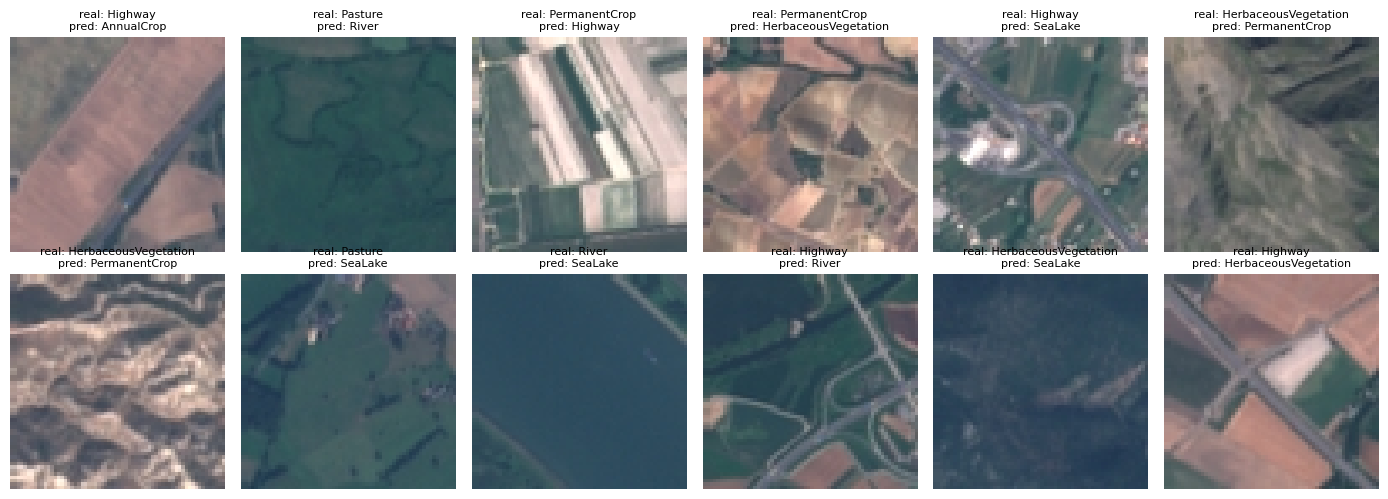

In [21]:
# Ejemplos mal clasificados
err = np.where(y_pred != y_test)[0]
sel = np.random.default_rng(seed).choice(err, 12, replace=False)
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for ax, i in zip(axes.ravel(), sel):
    ax.imshow(X_test[i]); ax.axis("off")
    ax.set_title(f"real: {class_names[y_test[i]]}\npred: {class_names[y_pred[i]]}", fontsize=8)
plt.tight_layout(); plt.show()

**Comentario.** El mejor modelo por validación resulta ser el base (M1, val = 0.632), pero su ventaja sobre M6 (0.626) y M7-SGD (0.626) es de menos de un punto, un empate dentro del ruido de la validación. Se reconocen bien *SeaLake* (recall ≈ 0.86), *Forest* (≈ 0.83) e *Industrial* (≈ 0.76), clases con colores y texturas característicos. Se reconocen mal *Highway* (≈ 0.33) y *PermanentCrop* (≈ 0.41): *Highway* se confunde con casi todas las demás (sobre todo *River* ≈ 16 %, *AnnualCrop* ≈ 11 %, *HerbaceousVegetation* y *Residential* ≈ 10 %), y *PermanentCrop* con *HerbaceousVegetation* (≈ 24 %) y *AnnualCrop* (≈ 12 %). *Residential* se confunde con *HerbaceousVegetation* (≈ 18 % de sus imágenes) e *Industrial* con *Residential* (≈ 12 %). Un MLP trabaja principalmente con el color medio y la distribución global de intensidades, no con formas ni bordes, por lo que no puede distinguir una carretera de un campo de cultivo con tonos parecidos.

## 10. Comparación final de todos los modelos

,params,epocas,train_acc,val_acc,test_acc,gap_train_val
modelo,,,,,,
M1 Base (512-256),6425866,100,0.7774,0.6323,0.6360,0.1450
M6 Combinado (L2 1e-3 + ES),6425866,65,0.6750,0.6262,0.6326,0.0489
M7 SGD (L2 1e-3 + ES),6425866,100,0.6979,0.6257,0.6291,0.0722
M2 L2 alpha=0.001,6425866,100,0.6878,0.6212,0.6378,0.0666
M5 Early Stopping,6425866,60,0.7116,0.6183,0.6304,0.0934
M2 L2 alpha=1e-05,6425866,100,0.7279,0.6153,0.6143,0.1126
M2 L2 alpha=0.0001,6425866,100,0.7206,0.6143,0.6126,0.1063
M7 RMSprop (L2 1e-3 + ES),6425866,41,0.5908,0.5733,0.5736,0.0175
M3 Dropout 0.1,6425866,100,0.6234,0.5509,0.5575,0.0725


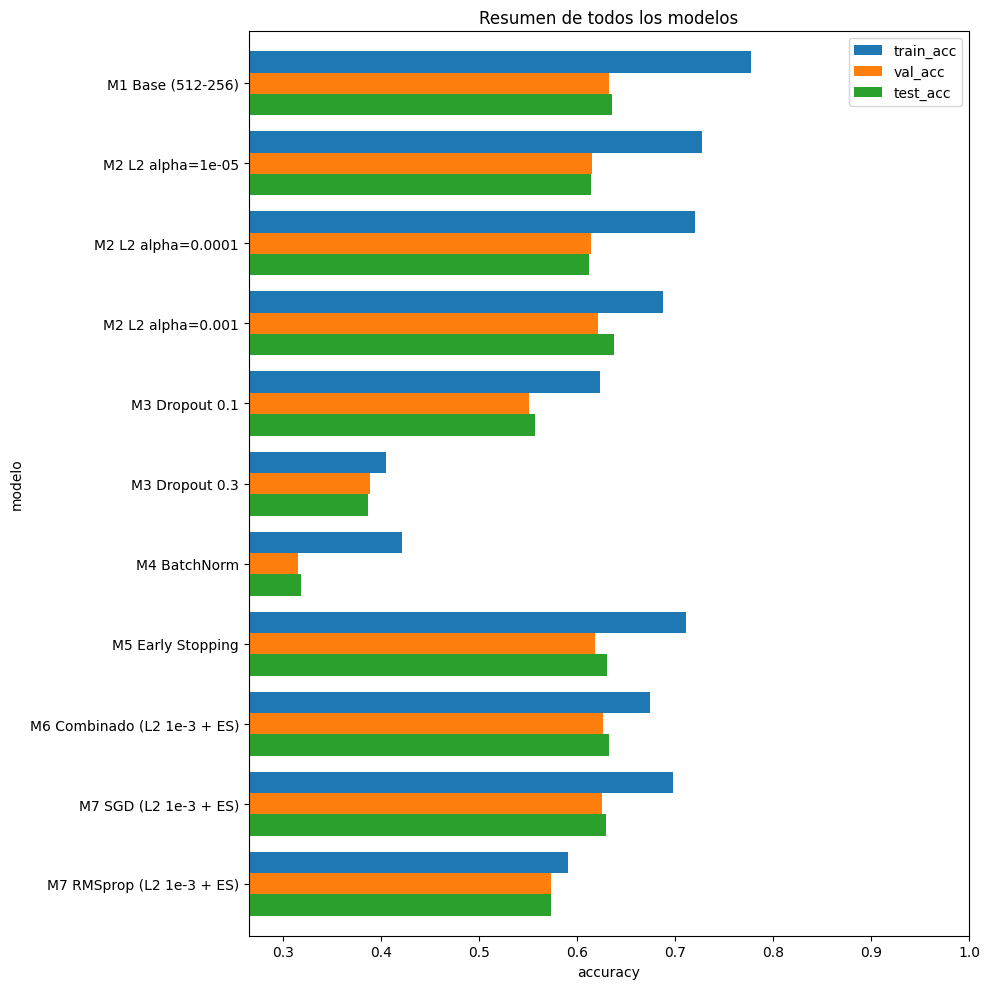

In [22]:
tabla = df[["params", "epocas", "train_acc", "val_acc", "test_acc", "gap_train_val"]].round(4)
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 60)
display(tabla.sort_values("val_acc", ascending=False))

ax = tabla[["train_acc", "val_acc", "test_acc"]].plot.barh(figsize=(10, 10), width=0.8)
ax.set_xlim(max(0, tabla[["train_acc", "val_acc", "test_acc"]].min().min() - 0.05), 1.0)
ax.invert_yaxis(); ax.set_xlabel("accuracy"); ax.set_title("Resumen de todos los modelos")
plt.tight_layout(); plt.show()

tabla.to_csv("resultados_p1.csv")

In [23]:
# Resumen automático a partir de los resultados reales
base = df.loc["M1 Base (512-256)"]; top = df.loc[mejor]
print(f"Modelo base:  train={base.train_acc:.3f}  val={base.val_acc:.3f}  test={base.test_acc:.3f}  gap={base.gap_train_val:.3f}")
print(f"Mejor modelo ({mejor}):  train={top.train_acc:.3f}  val={top.val_acc:.3f}  test={top.test_acc:.3f}  gap={top.gap_train_val:.3f}")
print(f"Mejora en validación respecto al base: {100*(top.val_acc-base.val_acc):+.2f} puntos")
print(f"Reducción del gap train-val: {100*(base.gap_train_val-top.gap_train_val):+.2f} puntos")

Modelo base:  train=0.777  val=0.632  test=0.636  gap=0.145
Mejor modelo (M1 Base (512-256)):  train=0.777  val=0.632  test=0.636  gap=0.145
Mejora en validación respecto al base: +0.00 puntos
Reducción del gap train-val: +0.00 puntos


## 11. Conclusiones

> **Nota:** las cifras de esta sección corresponden a la tabla de la sección 10 (entrenamiento en GPU, 100 épocas como máximo, una sola semilla por modelo).

**Rendimiento del modelo vanilla.** Una red densa de dos capas ocultas (512-256, 6,4 M de parámetros) alcanza ≈ 0.63 de accuracy en test, un resultado modesto pero esperable: la red recibe la imagen aplanada y no aprovecha la estructura espacial. Las clases con colores y texturas característicos (*SeaLake*, *Forest*, *Industrial*) se reconocen bien y las que dependen de formas (*Highway*, *River*) o se parecen en color (*PermanentCrop*, *AnnualCrop*, *HerbaceousVegetation*) se confunden.

**Sobreaprendizaje.** El modelo base memoriza el conjunto de entrenamiento: con 100 épocas el gap train-val llega a ≈ 14.5 puntos y la *loss* de validación crece tras la época ≈ 56. Con solo 30 épocas el modelo aún no sobreajustaba (el gap era ≈ 5 puntos), por lo que fue necesario entrenar más tiempo para poder medir el efecto de las regularizaciones.

**Efecto de cada regularización** (accuracy de validación / test y gap train-val; base: 0.632 / 0.636 / 14.5):
- *L2*: con `alpha` = 1e-3 reduce el gap a ≈ 6.7 puntos sin perder accuracy de test (0.621 / 0.638); con 1e-5 y 1e-4 el efecto es pequeño (gap ≈ 11).
- *Early Stopping*: mantiene la accuracy del base (0.618 / 0.630) con 40 épocas menos y un gap algo menor (≈ 9.3), pero no regulariza el modelo: solo elige el momento de mejor generalización.
- *Dropout*: empeora el modelo (val ≈ 0.55 con 0.1 y ≈ 0.39 con 0.3) por *underfitting*; se descarta.
- *BatchNorm*: no funciona en esta configuración (val ≈ 0.32; discrepancia entre entrenamiento e inferencia que no se ha logrado resolver); se descarta.
- *Combinación L2 + Early Stopping (M6)*: 0.626 / 0.633 con el menor gap entre los modelos que aprenden bien (≈ 4.9 puntos) y 65 épocas. Es la mejor opción en términos de sobreaprendizaje, aunque no mejora la accuracy.
- *Optimizadores (M7)*: SGD iguala a Adam (0.626 / 0.629) pero es más lento y agota las 100 épocas; RMSprop con los parámetros por defecto es peor (0.573 / 0.574).

**Selección del modelo.** Por accuracy de validación el mejor es formalmente el modelo base (0.632), pero su diferencia con M6 y con M7-SGD (≈ 0.626) está dentro del ruido. Dado que M6 obtiene lo mismo con un tercio del gap y menos épocas, sería la elección razonable si hubiera que desplegar uno.

**Lecciones.** (1) Reducir el gap no implica mejorar la accuracy: la regularización bajó el sobreaprendizaje de ≈ 14.5 a ≈ 4.9 puntos, pero la accuracy de test se queda en ≈ 0.63 en todos los modelos que aprenden bien. (2) Más técnicas no implican mejor resultado: Dropout y BatchNorm empeoraron el modelo. (3) Hay que comprobar que el modelo realmente sobreajusta antes de regularizar: con entrenamientos cortos las regularizaciones no tienen nada que corregir. (4) Las diferencias de uno o dos puntos están dentro del ruido de la validación y no son concluyentes con una sola semilla.

**Limitaciones y trabajo futuro.** La accuracy de un MLP en EuroSAT queda limitada por la arquitectura, no por la regularización. El tamaño de la red (512-256) no se ha optimizado. Las CNN (práctica 2), el *data augmentation* (giros y rotaciones, muy apropiados en imágenes de satélite) y el *transfer learning* son las vías naturales de mejora. También quedaría por investigar la causa del fallo de BatchNorm (por ejemplo colocándola antes de la activación) y repetir los experimentos con varias semillas para dar intervalos de confianza.